# CIFAR-10 con una red neuronal densa
## Entrenamiento, evolución de la pérdida y evaluación

**Objetivo:** entrenar una red densa para clasificar imágenes de CIFAR-10 en 10 categorías, observar la evolución de la función de pérdida y el accuracy, y registrar cuántas épocas se utilizaron.

> CIFAR-10 contiene imágenes RGB de 32 × 32 píxeles. Para usar una red densa, cada imagen se aplana a un vector de 3.072 valores. En este experimento la pérdida principal será *categorical cross-entropy*, apropiada para clasificación multiclase. También registraremos MSE como métrica complementaria, no como función de pérdida principal.

**Requisitos:** TensorFlow 2.x, NumPy y Matplotlib. Puede ejecutarse en Google Colab o en un entorno local con TensorFlow instalado.

In [ ]:
# Si lo necesitas en un entorno local, descomenta:
# %pip install tensorflow matplotlib numpy

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

TensorFlow: 2.21.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1. Cargar y preparar los datos

Usaremos el conjunto oficial de entrenamiento para crear dos particiones: entrenamiento y validación. El conjunto de prueba se reserva para la evaluación final, después del entrenamiento.

In [ ]:
class_names = [
    "Avión", "Automóvil", "Ave", "Gato", "Ciervo",
    "Perro", "Rana", "Caballo", "Barco", "Camión"
]

(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Convertir píxeles de [0, 255] a [0, 1]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Las etiquetas vienen como enteros entre 0 y 9.
# Las convertimos a vectores one-hot para categorical cross-entropy.
y_train_full = tf.keras.utils.to_categorical(y_train_full.squeeze(), 10)
y_test_onehot = tf.keras.utils.to_categorical(y_test.squeeze(), 10)

# Mezclar de forma reproducible y separar 5.000 imágenes para validación.
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train_full))
val_idx = indices[:5000]
train_idx = indices[5000:]

x_val, y_val = x_train_full[val_idx], y_train_full[val_idx]
x_train, y_train = x_train_full[train_idx], y_train_full[train_idx]

print(f"Entrenamiento: {x_train.shape[0]} imágenes")
print(f"Validación:    {x_val.shape[0]} imágenes")
print(f"Prueba:        {x_test.shape[0]} imágenes")
print("Forma de cada imagen:", x_train.shape[1:])

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2760s 16us/step
Entrenamiento: 45000 imágenes
Validación:    5000 imágenes
Prueba:        10000 imágenes
Forma de cada imagen: (32, 32, 3)


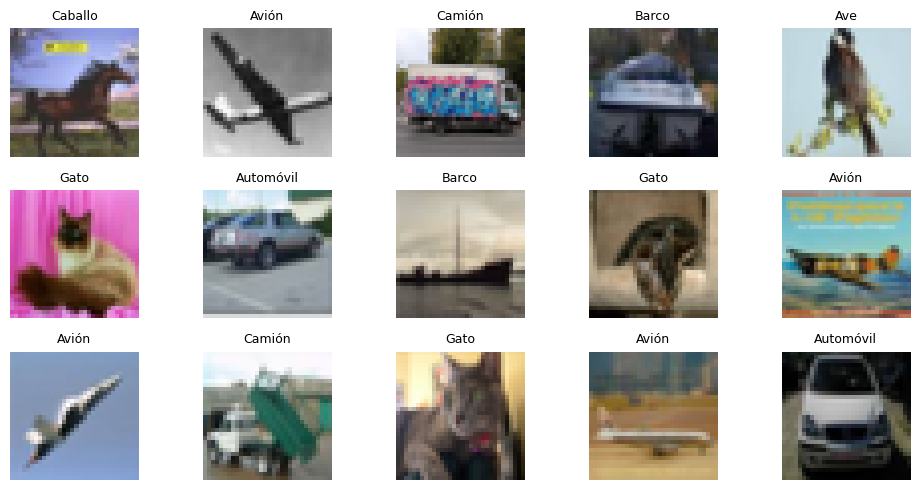

In [ ]:
# Visualizar algunas imágenes y sus etiquetas
plt.figure(figsize=(10, 5))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[np.argmax(y_train[i])], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Construir una red neuronal densa

La capa `Flatten` transforma cada imagen de 32 × 32 × 3 en un vector de 3.072 características. Después, las capas `Dense` aprenden combinaciones de esas características. Esta arquitectura sirve como línea base; no aprovecha explícitamente la estructura espacial de la imagen como lo haría una CNN.

Fijate bien en los comentarios para terminar el código faltante.

In [ ]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation=""), #Escoge un modelo entre relu, o sigmoid
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(256, activation=""), #Escoge un modelo entre relu, o sigmoid
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.MeanSquaredError(name="mse")
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Entrenar y registrar las épocas

El entrenamiento permite hasta 40 épocas con un batch size de 128, pero `EarlyStopping` puede detenerlo antes si la pérdida de validación deja de mejorar. Por eso, el número real de épocas se obtiene de `len(history.history["loss"])`, no se supone de antemano.

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

max_epochs = #Indica el numero de epocas
start_time = time.time()

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=max_epochs,
    batch_size=,#Indica el tamaño del batch
    callbacks=callbacks,
    verbose=1
)

elapsed_seconds = time.time() - start_time
epochs_used = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

print(f"\nÉpocas ejecutadas: {epochs_used} de {max_epochs} máximas")
print(f"Época con menor val_loss: {best_epoch}")
print(f"Tiempo de entrenamiento: {elapsed_seconds / 60:.2f} minutos")
print(f"Menor pérdida de validación registrada: {min(history.history['val_loss']):.4f}")

Epoch 1/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.2555 - loss: 2.0281 - mse: 0.0837 - val_accuracy: 0.3324 - val_loss: 1.8499 - val_mse: 0.0787 - learning_rate: 0.0010
Epoch 2/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 50ms/step - accuracy: 0.3148 - loss: 1.8838 - mse: 0.0799 - val_accuracy: 0.3582 - val_loss: 1.7873 - val_mse: 0.0773 - learning_rate: 0.0010
Epoch 3/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 19s 46ms/step - accuracy: 0.3316 - loss: 1.8321 - mse: 0.0785 - val_accuracy: 0.3686 - val_loss: 1.7635 - val_mse: 0.0765 - learning_rate: 0.0010
Epoch 4/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 16s 46ms/step - accuracy: 0.3453 - loss: 1.7973 - mse: 0.0773 - val_accuracy: 0.3930 - val_loss: 1.7169 - val_mse: 0.0751 - learning_rate: 0.0010
Epoch 5/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 51ms/step - accuracy: 0.3594 - loss: 1.7611 - mse: 0.0762 - val_accuracy: 0.3788 - val_loss: 1.7271 - val_mse: 0.0755 - learning_rate: 0.0010
Epoch 6/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 44ms/step - accuracy: 0.36

## 4. Graficar la evolución del entrenamiento

- **Loss:** entropía cruzada; es la función que el optimizador intenta minimizar.
- **MSE:** error cuadrático medio entre las probabilidades predichas y las etiquetas one-hot; se registra como métrica complementaria.
- **Accuracy:** proporción de imágenes clasificadas correctamente.

Compara las curvas de entrenamiento y validación. Si la pérdida de entrenamiento sigue bajando mientras la de validación deja de mejorar o sube, puede haber sobreajuste.

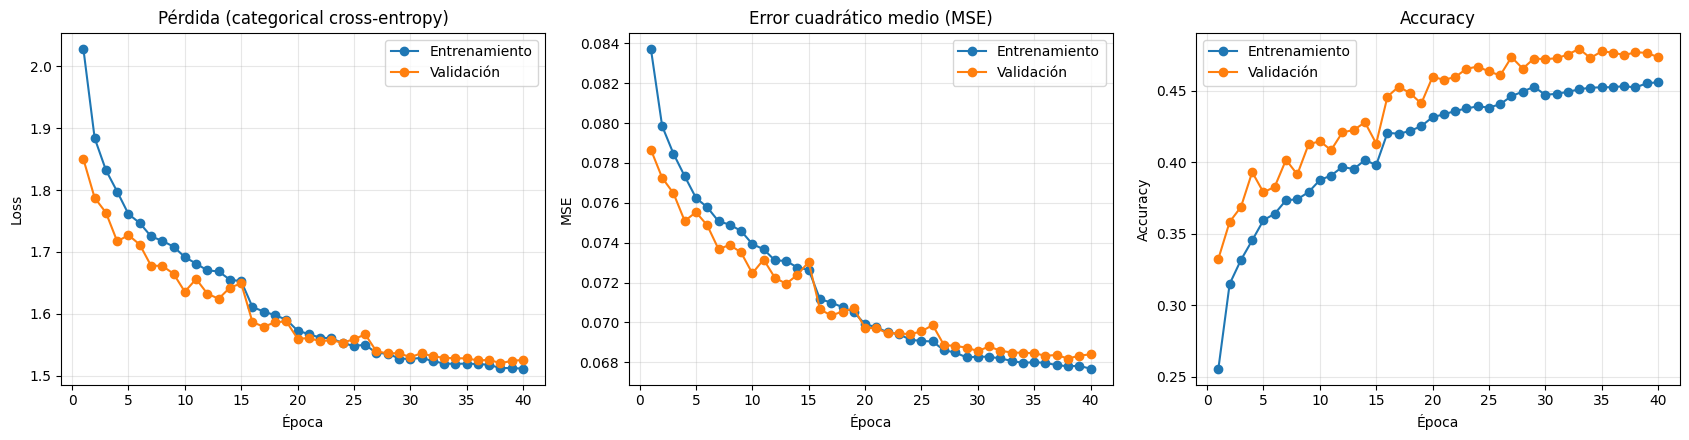

In [ ]:
epochs_range = range(1, epochs_used + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Pérdida principal: categorical cross-entropy
axes[0].plot(epochs_range, history.history["loss"], marker="o", label="Entrenamiento")
axes[0].plot(epochs_range, history.history["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (categorical cross-entropy)")
#Completa las etiquetas faltantes
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# MSE complementario
axes[1].plot(epochs_range, history.history["mse"], marker="o", label="Entrenamiento")
axes[1].plot(epochs_range, history.history["val_mse"], marker="o", label="Validación")
axes[1].set_title("Error cuadrático medio (MSE)")
#Completa las etiquetas faltantes
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Accuracy
axes[2].plot(epochs_range, history.history["accuracy"], marker="o", label="Entrenamiento")
axes[2].plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validación")
axes[2].set_title("Accuracy")
#Completa las etiquetas faltantes
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

## 5. Evaluación final con el conjunto de prueba

El conjunto de prueba no se utilizó para ajustar los pesos ni para elegir la época. Esta evaluación ofrece una estimación final del desempeño sobre datos reservados.

In [ ]:
test_results = model.evaluate(x_test, y_test_onehot, verbose=0)
test_loss, test_accuracy, test_mse = test_results

print(f"Test loss (cross-entropy): {test_loss:.4f}")
print(f"Test accuracy:             {test_accuracy:.2%}")
print(f"Test MSE:                  {test_mse:.4f}")

Test loss (cross-entropy): 1.5050
Test accuracy:             48.30%
Test MSE:                  0.0675


# Realizar completamente la parte de verificación de entrenamiento

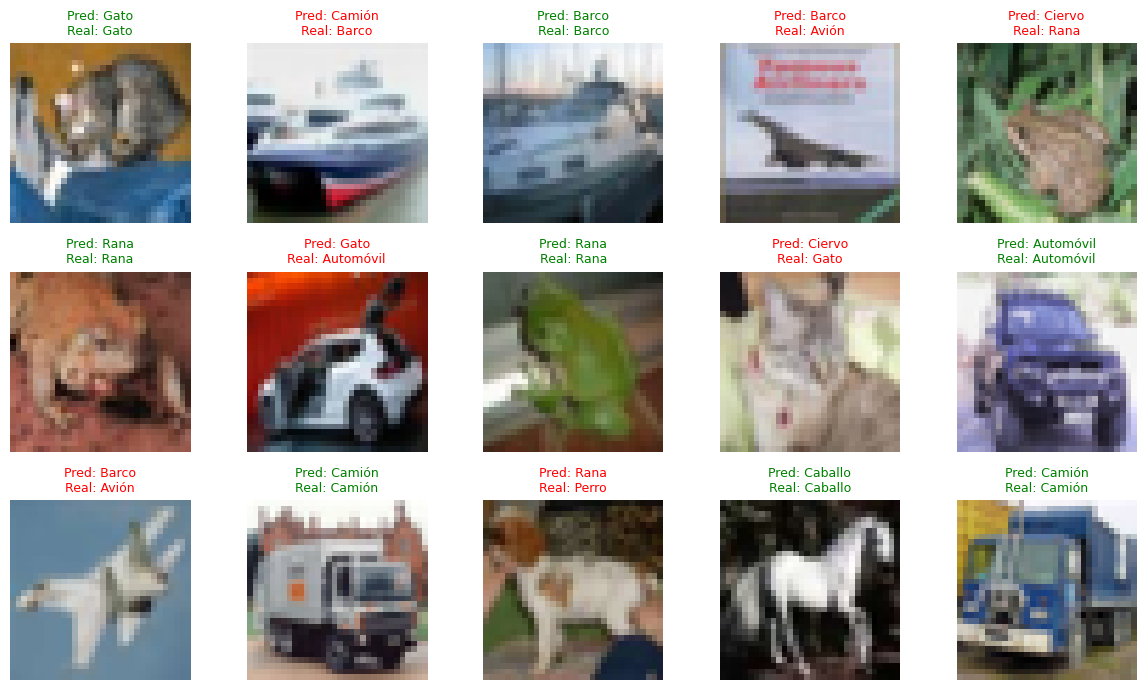

In [ ]:
# Mostrar predicciones de algunas imágenes del conjunto de prueba


## 6. Guardar el modelo

El archivo `.keras` conserva la arquitectura y los pesos para volver a cargar el modelo en Python. Para ejecutarlo directamente en un navegador, posteriormente se puede convertir a TensorFlow.js; esa conversión requiere preparar el entorno correspondiente.

In [ ]:
import os
import shutil

from google.colab import drive

# Evitamos el error verificando si Drive ya está montado de forma activa
if not os.path.exists('/content/drive/MyDrive'):
    # Si la carpeta /content/drive existe pero no está montada de forma activa, la vaciamos para evitar conflictos
    if os.path.exists('/content/drive'):
        try:
            shutil.rmtree('/content/drive')
        except Exception:
            pass
    print("Montando Google Drive...")
    drive.mount('/content/drive', force_remount=True)
else:
    print("Google Drive ya se encuentra montado y accesible.")

# Ruta del modelo entrenado en Colab
origen = "/content/cifar10_dense_model.keras"

# Ruta de tu carpeta actual en Google Drive
destino = "/content/drive/MyDrive/Colab Notebooks/"

# Crear carpeta si no existe
os.makedirs(destino, exist_ok=True)

# Copiar el modelo
archivo_destino = os.path.join(
    destino,
    "cifar10_dense_model.keras"
)

if os.path.exists(origen):
    shutil.copy2(origen, archivo_destino)

    print("¡Modelo guardado correctamente!")
    print("Ruta:", archivo_destino)
    print("Tamaño:", round(os.path.getsize(archivo_destino) / (1024**2), 2), "MB")
else:
    print("No se encuentra el modelo original.")

Google Drive ya se encuentra montado y accesible.
¡Modelo guardado correctamente!
Ruta: /content/drive/MyDrive/Colab Notebooks/cifar10_dense_model.keras
Tamaño: 19.57 MB


In [ ]:
from google.colab import files

files.download("/content/drive/MyDrive/Colab Notebooks/Deep/cifar10_dense_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>